In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from matplotlib.patches import Ellipse, Patch
import matplotlib.pyplot as plt
from itertools import combinations

In [2]:
belief_col = ['Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol','Belief_opinion_on_the_number_of_immigrants_in_america_Symbol']

In [3]:
anes_window_label = '2024-08-11'

In [4]:
gss_window_label = '2024-04-07'

In [9]:
anes_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/anes2024target.csv",)
anes_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2544,3.436283,3.411062,3.460619,3.404381,3.469027,3.394690,3.478761,3.388042,3.486737
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2931,3.454406,3.432567,3.477011,3.425670,3.483525,3.416839,3.491207,3.412251,3.496944
2,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1699,3.408941,3.376726,3.439842,3.368771,3.449047,3.354997,3.460224,3.346466,3.474047
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2501,3.537653,3.512189,3.561366,3.505254,3.567863,3.497351,3.575744,3.488595,3.583647
4,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1014,3.200466,3.158508,3.240093,3.149184,3.252914,3.131702,3.270396,3.118852,3.284470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,state_simple,North Dakota,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024,28,4.750000,4.642857,4.892857,4.607143,4.892857,4.535714,4.928571,4.464286,4.964286
130,state_simple,South Dakota,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024,10,4.600000,4.400000,4.800000,4.300000,4.800000,4.200000,4.900000,4.100000,4.902500
131,state_simple,Rhode Island,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024,14,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
132,state_simple,Hawaii,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024,9,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [10]:
gss_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/gss2024target.csv",)
gss_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1394,3.552367,3.518537,3.586083,3.509326,3.596844,3.496341,3.609039,3.486352,3.616930
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1698,3.530035,3.502945,3.559482,3.492933,3.568316,3.482303,3.575972,3.468183,3.584806
2,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,gss,731,3.253078,3.210670,3.292750,3.199726,3.305062,3.186047,3.320109,3.173700,3.335157
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1288,3.725155,3.693975,3.758540,3.684783,3.769410,3.671584,3.779503,3.657570,3.791945
4,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1043,3.524449,3.485139,3.562800,3.474593,3.573346,3.458245,3.585858,3.445829,3.596381
5,income,100k+,Belief_opinion_on_the_number_of_immigrants_in_...,gss,737,3.462687,3.419267,3.504749,3.407056,3.519674,3.392062,3.534600,3.375848,3.546811
6,income,50-100k,Belief_opinion_on_the_number_of_immigrants_in_...,gss,941,3.635494,3.597237,3.676939,3.585547,3.686504,3.572742,3.702444,3.558980,3.714160
7,income,<50k,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1058,3.499055,3.460302,3.535917,3.448960,3.547259,3.435681,3.559594,3.420558,3.569991
8,eth,Non-white,Belief_opinion_on_the_number_of_immigrants_in_...,gss,938,3.238806,3.201493,3.277186,3.187633,3.288913,3.171642,3.302772,3.156690,3.313433
9,eth,White,Belief_opinion_on_the_number_of_immigrants_in_...,gss,2109,3.672357,3.648174,3.699934,3.641015,3.706496,3.629635,3.715529,3.623495,3.725012


In [11]:
df_obs =pd.concat([anes_obs, gss_obs], ignore_index=True)
df_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2544,3.436283,3.411062,3.460619,3.404381,3.469027,3.394690,3.478761,3.388042,3.486737
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2931,3.454406,3.432567,3.477011,3.425670,3.483525,3.416839,3.491207,3.412251,3.496944
2,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1699,3.408941,3.376726,3.439842,3.368771,3.449047,3.354997,3.460224,3.346466,3.474047
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2501,3.537653,3.512189,3.561366,3.505254,3.567863,3.497351,3.575744,3.488595,3.583647
4,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1014,3.200466,3.158508,3.240093,3.149184,3.252914,3.131702,3.270396,3.118852,3.284470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,education,Non-college,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1688,3.635664,3.605948,3.665284,3.595379,3.676600,3.582938,3.688981,3.574052,3.695557
146,vote,Democratic,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1139,3.061457,3.028095,3.091308,3.017471,3.100966,3.006980,3.115891,2.995610,3.129061
147,vote,Republican,Belief_opinion_on_the_number_of_immigrants_in_...,gss,844,4.311611,4.275877,4.345972,4.266588,4.356635,4.254739,4.366114,4.245261,4.376777
148,vote,Other,Belief_opinion_on_the_number_of_immigrants_in_...,gss,48,3.625000,3.437500,3.812500,3.375000,3.875000,3.312500,3.937500,3.250000,4.000000


In [12]:
def load_llm_predictions(model_dir, question_id, grouping_var):
    """
    Load and stack all per-demographic prediction files for one question.
    
    model_dir          : directory containing prediction CSVs
    question_id       : e.g. 'IMMLEVEL'
    grouping_var      : list of grouping variable names
    """
    records = []

    for gvar in grouping_var:
        path = f"{model_dir}/group_{gvar}_predictions.csv"

        df = pd.read_csv(path)

        # First column is always the category label — rename it consistently
        df = df.rename(columns={df.columns[0]: 'category'})
        df['grouping_var'] = gvar
        df['question_id']  = question_id
        records.append(df)

    llm_df = pd.concat(records, ignore_index=True)

    return llm_df

In [13]:
def compute_metrics(plot_df, n_boot=1000, seed=42):
    """
    Compute bias, RMSE, correlation, and 95% CI coverage,
    each with bootstrapped CIs.
    """
    rng = np.random.default_rng(seed)
    x = plot_df['pred_mean'].values
    y = plot_df['obs_mean'].values
    n = len(x)

    def point_metrics(x, y):
        y_range = y.max() - y.min()
        bias     = np.mean(x - y)
        rmse     = np.sqrt(np.mean((x - y) ** 2))
        corr,p     = stats.spearmanr(x, y)
        if y_range > 0:
            nbias = bias / y_range
            nrmse = rmse / y_range
        else:
            nbias = np.nan
            nrmse = np.nan
        # 95% coverage: is obs_mean inside llm 95% CI?
        coverage = np.mean(
            (plot_df['pred_lower_95'].values <= y) &
            (y <= plot_df['pred_upper_95'].values)
        )
        return nbias, nrmse, corr, coverage

    nbias0, nrmse0, corr0, cov0 = point_metrics(x, y)

    # Bootstrap CIs on metrics
    boot = {'bias': [], 'rmse': [], 'corr': [], 'coverage': []}
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        b, r, c, cv = point_metrics(x[idx], y[idx])
        boot['bias'].append(b)
        boot['rmse'].append(r)
        boot['corr'].append(c)
        boot['coverage'].append(cv)

    def ci(arr, level=95):
        alpha = (100 - level) / 2
        return (np.percentile(arr, alpha), np.percentile(arr, 100 - alpha))

    return {
        'bias_mean':     nbias0,     'bias_ci':     ci(boot['bias']),
        'rmse_mean':     nrmse0,     'rmse_ci':     ci(boot['rmse']),
        'corr_mean':     corr0,     'corr_ci':     ci(boot['corr']),
        'coverage_mean': cov0,      'coverage_ci': ci(boot['coverage']),
    }

In [14]:
def build_plot_df(llm_df, obs_df):
    """
    Merge LLM predictions with survey observations.
    One row = one scatter dot.
    """
    merged = obs_df.merge(
        llm_df,
        on=['grouping_var', 'category', 'question_id','benchmark'],
        how='inner'
    )

    return merged

In [42]:
def plot_scatter_with_uncertainty_ellipses(ax, plot_df, metrics, ci_level=95,
                                           question_id=None, benchmark=None,
                                           ceiling_metrics=None):
    from matplotlib.lines import Line2D

    x_col = 'pred_mean'
    y_col = 'obs_mean'
    x_lo = f'pred_lower_{ci_level}'
    x_hi = f'pred_upper_{ci_level}'
    y_lo = f'obs_lower_{ci_level}'
    y_hi = f'obs_upper_{ci_level}'
    
    # Filter first so scales/metrics text match what is shown.
    if question_id is not None:
        plot_df = plot_df[plot_df['question_id'] == question_id]
    if benchmark is not None:
        plot_df = plot_df[plot_df['benchmark'] == benchmark]

    if plot_df.empty:
        ax.set_title('No data after filtering')
        ax.axis('off')
        return

    all_vals = np.concatenate([plot_df[x_col].values, plot_df[y_col].values])
    val_min, val_max = all_vals.min(), all_vals.max()
    pad = (val_max - val_min) * 0.15 if val_max > val_min else 0.1
    axis_min = val_min - pad
    axis_max = val_max + pad

    # Color by target dataset (benchmark).
    datasets = sorted(plot_df['benchmark'].astype(str).unique())
    color_cycle = ['#1f77b4', '#d62728']
    color_map = {ds: color_cycle[i] for i, ds in enumerate(datasets)}

    # Marker by sub-demographic (grouping_var + category).
    subgroup_col = (
        plot_df['grouping_var'].astype(str) + ': ' + plot_df['category'].astype(str)
    )
    plot_df = plot_df.assign(subgroup=subgroup_col)
    subgroups = sorted(plot_df['subgroup'].unique())
    marker_cycle = ['o', 's', '^', 'D', 'v', 'P', 'X','H', '*', '<', '>', 'h', '8', 'p','+', 
                    'x', '1', '2', '3', '4', '|']
    marker_map = {sg: marker_cycle[i % len(marker_cycle)] for i, sg in enumerate(subgroups)}

    # Uncertainty ellipses.
    ellipse_added = False
    for _, row in plot_df.iterrows():
        if any(pd.isna(row.get(c)) for c in [x_lo, x_hi, y_lo, y_hi]):
            continue
        ellipse = Ellipse(
            xy=(row[x_col], row[y_col]),
            width=row[x_hi] - row[x_lo],
            height=row[y_hi] - row[y_lo],
            alpha=0.25,
            facecolor='#B0B0B0',
            edgecolor='#B0B0B0',
            linewidth=0.5,
            zorder=1
        )
        ax.add_patch(ellipse)
        ellipse_added = True

    # Scatter: color = dataset, marker = sub-demographic.
    for (ds, sg), grp in plot_df.groupby(['benchmark', 'subgroup']):
        ax.scatter(
            grp[x_col], grp[y_col],
            color=color_map[str(ds)],
            marker=marker_map[sg],
            alpha=0.85,
            s=65,
            zorder=5,
            edgecolors='white',
            linewidth=0.4
        )

    # Diagonal reference line.
    ax.plot(
        [axis_min, axis_max], [axis_min, axis_max],
        'k--', lw=1.3, zorder=4
    )

    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('MrP Predicted Mean (LLM)', fontsize=11)
    ylabel = f'{benchmark} Observed Mean' if benchmark is not None else 'Observed Mean'
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'{question_id.removesuffix("_Symbol")}' if question_id else '', fontsize=12)
    ax.grid(True, alpha=0.3)

    # Legend 1: color -> dataset.
    color_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None',
            markerfacecolor=color_map[ds], markeredgecolor='white',
            markeredgewidth=0.5, markersize=8, label=ds
        )
        for ds in datasets
    ]
    if ellipse_added:
        color_handles.append(
            Patch(facecolor='#B0B0B0', alpha=0.25, label=f'{ci_level}% CI ellipse')
        )
    legend_colors = ax.legend(
        handles=color_handles,
        title='Target dataset',
        fontsize=8,
        title_fontsize=9,
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0
    )
    ax.add_artist(legend_colors)

    # Legend 2: marker -> sub-demographic.
    marker_handles = [
        Line2D(
            [0], [0], marker=marker_map[sg], linestyle='None',
            markerfacecolor='lightgray', markeredgecolor='black',
            markeredgewidth=0.5, markersize=8, label=sg
        )
        for sg in subgroups
    ]
    ax.legend(
        handles=marker_handles,
        title='Sub-demographic',
        fontsize=7,
        title_fontsize=9,
        loc='upper left',
        bbox_to_anchor=(1.02, 0.52),
        borderaxespad=0.0
    )

    # Main evaluation metrics box in top-left.
    textstr = (
        f'$\\mathbf{{Performance}}$\n'
        f'Bias: {metrics["bias_mean"]:.3f} '
        f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
        f'RMSE: {metrics["rmse_mean"]:.3f} '
        f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
        f'Corr: {metrics["corr_mean"]:.3f} '
        f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
        f'95% Coverage: {metrics["coverage_mean"]:.2f} '
        f'({metrics["coverage_ci"][0]:.2f}, {metrics["coverage_ci"][1]:.2f})\n'
        f'N: {len(plot_df)}'
    )
    ax.text(
        0.03, 0.97, textstr,
        transform=ax.transAxes, fontsize=8,
        va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    )

    # ceiling metrics box in bottom-right.
    if ceiling_metrics is not None:
        ceiling_text = (
            f'$\\mathbf{{Cross\\!-\!Target\\ Consistency}}$\n'
            f'Absolute Bias: {ceiling_metrics["bias_mean"]:.3f}\n '
            f'RMSE: {ceiling_metrics["rmse_mean"]:.3f}\n '
            f'Corr: {ceiling_metrics["corr_mean"]:.3f}\n '
            f'Average coverage: {ceiling_metrics["cov_sym_mean"]:.2f}\n '
            f'N: {ceiling_metrics["n"]}'
        )
        ax.text(
            0.97, 0.03, ceiling_text,
            transform=ax.transAxes, fontsize=8,
            va='bottom', ha='right',
            bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.55)
        )

<>:156: SyntaxWarning: invalid escape sequence '\!'
<>:156: SyntaxWarning: invalid escape sequence '\!'
/tmp/ipykernel_86332/1455368263.py:156: SyntaxWarning: invalid escape sequence '\!'
  f'$\\mathbf{{Cross\\!-\!Target\\ Consistency}}$\n'


In [16]:
df_obs

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2544,3.436283,3.411062,3.460619,3.404381,3.469027,3.394690,3.478761,3.388042,3.486737
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2931,3.454406,3.432567,3.477011,3.425670,3.483525,3.416839,3.491207,3.412251,3.496944
2,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1699,3.408941,3.376726,3.439842,3.368771,3.449047,3.354997,3.460224,3.346466,3.474047
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2501,3.537653,3.512189,3.561366,3.505254,3.567863,3.497351,3.575744,3.488595,3.583647
4,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1014,3.200466,3.158508,3.240093,3.149184,3.252914,3.131702,3.270396,3.118852,3.284470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,education,Non-college,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1688,3.635664,3.605948,3.665284,3.595379,3.676600,3.582938,3.688981,3.574052,3.695557
146,vote,Democratic,Belief_opinion_on_the_number_of_immigrants_in_...,gss,1139,3.061457,3.028095,3.091308,3.017471,3.100966,3.006980,3.115891,2.995610,3.129061
147,vote,Republican,Belief_opinion_on_the_number_of_immigrants_in_...,gss,844,4.311611,4.275877,4.345972,4.266588,4.356635,4.254739,4.366114,4.245261,4.376777
148,vote,Other,Belief_opinion_on_the_number_of_immigrants_in_...,gss,48,3.625000,3.437500,3.812500,3.375000,3.875000,3.312500,3.937500,3.250000,4.000000


In [ ]:
    # here if in df_obs, for a certain question_id,if there are rows with benchmark = anes2024, then load base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}"
    # in the final llm_df add a column of benchmark,
    # if there is also for the same question id some rows with benchmark = gss, then also load load base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}",
    # and upate the benchmark column in the final llm_df accordingly.
    # so if for a certain question_id there are two unique values of benchmark in df_obs, then in the final llm_df for that question_id there will be two unique values of benchmark, and the corresponding rows will be duplicated accordingly.

: 

: 

: 

In [17]:
# Build llm_df with one copy per observed benchmark for each question_id
grouping_vars = ['sex', 'age', 'income', 'eth', 'education', 'vote','state']

def infer_window_label(benchmark):
    b = str(benchmark).lower()
    if 'anes' in b:
        return anes_window_label
    if 'gss' in b:
        return gss_window_label

llm_parts = []
for col in belief_col:
    base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}"

    # Which benchmarks are actually present for this question in obs data?
    q_benchmarks = (
        df_obs.loc[df_obs['question_id'] == col, 'benchmark']
        .dropna()
        .astype(str)
        .unique()
    )

    for benchmark in q_benchmarks:
        window_label = infer_window_label(benchmark)
        model_dir = f"{base_dir}/{col}_{window_label}_stan_output"
        belief_df = load_llm_predictions(
            model_dir=model_dir,
            question_id=col,
            grouping_var=grouping_vars
        )
        belief_df['benchmark'] = benchmark
        llm_parts.append(belief_df)

llm_df = pd.concat(llm_parts, ignore_index=True) if llm_parts else pd.DataFrame()
llm_df

,category,pred_mean,pred_median,pred_lower_95,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,grouping_var,question_id,benchmark
0,Female,4.824376,4.827118,4.779064,4.864587,4.783399,4.859524,4.794210,4.853782,4.799598,4.847476,0.024329,sex,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024
1,Male,4.749418,4.751312,4.679161,4.804311,4.698637,4.796339,4.714412,4.782465,4.722953,4.777300,0.029347,sex,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024
2,18-34,4.794995,4.796893,4.731964,4.841704,4.742875,4.835727,4.759387,4.829439,4.765469,4.821595,0.028278,age,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024
3,35-54,4.849712,4.852734,4.804243,4.886921,4.810077,4.881942,4.820990,4.874687,4.827295,4.869906,0.021720,age,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024
4,55+,4.743999,4.745235,4.677450,4.801351,4.685167,4.791220,4.703159,4.783596,4.713429,4.776021,0.032406,age,Belief_opinion_on_the_extent_to_which_this_ind...,anes2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,Virginia,3.117205,3.117918,2.983390,3.273555,2.990901,3.257826,3.008011,3.226293,3.031341,3.210062,0.081528,state,Belief_opinion_on_the_number_of_immigrants_in_...,gss
197,Washington,3.071016,3.071481,2.929199,3.237386,2.951783,3.211182,2.967659,3.172205,2.986118,3.144372,0.079830,state,Belief_opinion_on_the_number_of_immigrants_in_...,gss
198,West Virginia,3.578102,3.578020,3.052520,4.089921,3.115498,3.996779,3.253735,3.901844,3.335137,3.842637,0.261056,state,Belief_opinion_on_the_number_of_immigrants_in_...,gss
199,Wisconsin,3.090001,3.088081,2.881086,3.307441,2.919971,3.273157,2.958402,3.222498,2.986118,3.193919,0.107770,state,Belief_opinion_on_the_number_of_immigrants_in_...,gss


In [18]:
plot_df = build_plot_df(llm_df, df_obs)
plot_df.head()

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_median,pred_lower_95,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2544,3.436283,3.411062,3.460619,3.404381,3.469027,...,3.411512,3.334692,3.511253,3.339037,3.500473,3.350630,3.478743,3.364528,3.460811,0.048445
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2931,3.454406,3.432567,3.477011,3.425670,3.483525,...,3.063705,2.966980,3.169230,2.978492,3.147890,3.001987,3.125974,3.016365,3.109155,0.051456
2,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1699,3.408941,3.376726,3.439842,3.368771,3.449047,...,3.162008,3.057643,3.270573,3.077435,3.263271,3.096763,3.236279,3.109526,3.215407,0.054658
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2501,3.537653,3.512189,3.561366,3.505254,3.567863,...,3.488836,3.399250,3.588417,3.415570,3.570002,3.426624,3.557864,3.445743,3.539714,0.048882
4,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1014,3.200466,3.158508,3.240093,3.149184,3.252914,...,2.844781,2.726387,2.977421,2.743892,2.948017,2.766474,2.925725,2.782198,2.909267,0.063944


In [19]:
plot_df['question_id'].unique()

array(['Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
       'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol'],
      dtype=object)

In [20]:
counts = (plot_df
              .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
              .nunique()
              .rename('n_obs_sources')
              .reset_index())
counts

,question_id,grouping_var,category,n_obs_sources
0,Belief_opinion_on_the_extent_to_which_this_ind...,age,18-34,1
1,Belief_opinion_on_the_extent_to_which_this_ind...,age,35-54,1
2,Belief_opinion_on_the_extent_to_which_this_ind...,age,55+,1
3,Belief_opinion_on_the_extent_to_which_this_ind...,education,College,1
4,Belief_opinion_on_the_extent_to_which_this_ind...,education,Non-college,1
5,Belief_opinion_on_the_extent_to_which_this_ind...,eth,Non-white,1
6,Belief_opinion_on_the_extent_to_which_this_ind...,eth,White,1
7,Belief_opinion_on_the_extent_to_which_this_ind...,income,100k+,1
8,Belief_opinion_on_the_extent_to_which_this_ind...,income,50-100k,1
9,Belief_opinion_on_the_extent_to_which_this_ind...,income,<50k,1


In [21]:
plot_df = plot_df.merge(counts, on=['question_id', 'grouping_var', 'category'])
plot_df['has_multiple_obs'] = plot_df['n_obs_sources'] > 1
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,n_obs_sources,has_multiple_obs
0,sex,Male,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2544,3.436283,3.411062,3.460619,3.404381,3.469027,...,3.511253,3.339037,3.500473,3.350630,3.478743,3.364528,3.460811,0.048445,2,True
1,sex,Female,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2931,3.454406,3.432567,3.477011,3.425670,3.483525,...,3.169230,2.978492,3.147890,3.001987,3.125974,3.016365,3.109155,0.051456,2,True
2,age,35-54,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1699,3.408941,3.376726,3.439842,3.368771,3.449047,...,3.270573,3.077435,3.263271,3.096763,3.236279,3.109526,3.215407,0.054658,2,True
3,age,55+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,2501,3.537653,3.512189,3.561366,3.505254,3.567863,...,3.588417,3.415570,3.570002,3.426624,3.557864,3.445743,3.539714,0.048882,2,True
4,age,18-34,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1014,3.200466,3.158508,3.240093,3.149184,3.252914,...,2.977421,2.743892,2.948017,2.766474,2.925725,2.782198,2.909267,0.063944,2,True
5,income,100k+,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1954,3.316413,3.287648,3.345178,3.280880,3.354202,...,3.178749,2.996480,3.162971,3.008683,3.146220,3.024521,3.128733,0.054367,2,True
6,income,<50k,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1620,3.547869,3.515723,3.580014,3.507338,3.589099,...,3.408707,3.183235,3.391694,3.208994,3.370682,3.223915,3.352876,0.063812,2,True
7,income,50-100k,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1391,3.475279,3.440861,3.508900,3.432217,3.518421,...,3.447520,3.270191,3.436704,3.290761,3.413192,3.304680,3.401732,0.049799,2,True
8,eth,Non-white,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,1508,3.265852,3.233766,3.300993,3.224599,3.311688,...,2.997892,2.781055,2.977329,2.800756,2.956368,2.810754,2.940216,0.059983,2,True
9,eth,White,Belief_opinion_on_the_number_of_immigrants_in_...,anes2024,3946,3.510158,3.490406,3.530192,3.484481,3.534989,...,3.465859,3.299087,3.441503,3.316526,3.428972,3.327971,3.415126,0.045430,2,True


In [22]:
def compute_obs_pairwise(plot_df, n_boot=250, seed=42):
    """
    For all (question_id, grouping_var, category) cells where both obs datasets exist,
    compute a single overall agreement between the two datasets.
    Each dot = one (question_id, grouping_var, category) cell.
    """
    rng = np.random.default_rng(seed)

    # Pivot so each row is one (question_id, grouping_var, category)
    # with one column per obs_dataset
    multi = plot_df[plot_df['has_multiple_obs']].copy()

    pairwise_records = []

    for (ds_a, ds_b) in combinations(multi['benchmark'].unique(), 2):
        df_a = multi[multi['benchmark'] == ds_a].set_index(
            ['question_id', 'grouping_var', 'category']
        )
        df_b = multi[multi['benchmark'] == ds_b].set_index(
            ['question_id', 'grouping_var', 'category']
        )

        # Align on shared cells
        shared_idx = df_a.index.intersection(df_b.index)

        a      = df_a.loc[shared_idx, 'obs_mean'].values
        b      = df_b.loc[shared_idx, 'obs_mean'].values
        ci_cols = {                                         # carry CIs for ellipses
            f'{ds_a}_lower_95': df_a.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_a}_upper_95': df_a.loc[shared_idx, 'obs_upper_95'].values,
            f'{ds_b}_lower_95': df_b.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_b}_upper_95': df_b.loc[shared_idx, 'obs_upper_95'].values,
        }

        # Build aligned dataframe — one row per dot on the scatter plot
        aligned_df = pd.DataFrame({
            'question_id':  [i[0] for i in shared_idx],
            'grouping_var': [i[1] for i in shared_idx],
            'category':     [i[2] for i in shared_idx],
            'obs_mean_a':   a,
            'obs_mean_b':   b,
            **ci_cols
        }).assign(ds_a=ds_a, ds_b=ds_b)

        pairwise_records.append(aligned_df)

    pairwise_df = pd.concat(pairwise_records, ignore_index=True)
    return pairwise_df

In [23]:
def compute_obs_pairwise_metrics(pairwise_df, ci_level=95, seed=42):
    """
    Compute agreement metrics between two observed benchmarks.
    """
    if pairwise_df is None or pairwise_df.empty:
        return None

    ds_a = pairwise_df['ds_a'].iloc[0]
    ds_b = pairwise_df['ds_b'].iloc[0]
    x_col = 'obs_mean_a'
    y_col = 'obs_mean_b'
    x_lo = f'{ds_a}_lower_{ci_level}'
    x_hi = f'{ds_a}_upper_{ci_level}'
    y_lo = f'{ds_b}_lower_{ci_level}'
    y_hi = f'{ds_b}_upper_{ci_level}'

    x = pairwise_df[x_col].values
    y = pairwise_df[y_col].values
    n = len(x)

    cov_a_in_b = np.mean((pairwise_df[y_lo].values <= x) & (x <= pairwise_df[y_hi].values))
    cov_b_in_a = np.mean((pairwise_df[x_lo].values <= y) & (y <= pairwise_df[x_hi].values))
    cov_sym = 0.5 * (cov_a_in_b + cov_b_in_a)

    y_range = y.max() - y.min()
    bias = abs(np.mean(x - y))
    rmse = np.sqrt(np.mean((x - y) ** 2))
    corr, _ = stats.spearmanr(x, y)
    nbias = bias / y_range if y_range > 0 else np.nan
    nrmse = rmse / y_range if y_range > 0 else np.nan

    return {
        'bias_mean': nbias,
        'rmse_mean': nrmse,
        'corr_mean': corr,
        'cov_sym_mean': cov_sym,
        'n': n,
    }

In [24]:
plot_df['question_id'].unique()

array(['Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
       'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol'],
      dtype=object)

/tmp/ipykernel_86332/1455368263.py:65: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/tmp/ipykernel_86332/1455368263.py:65: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


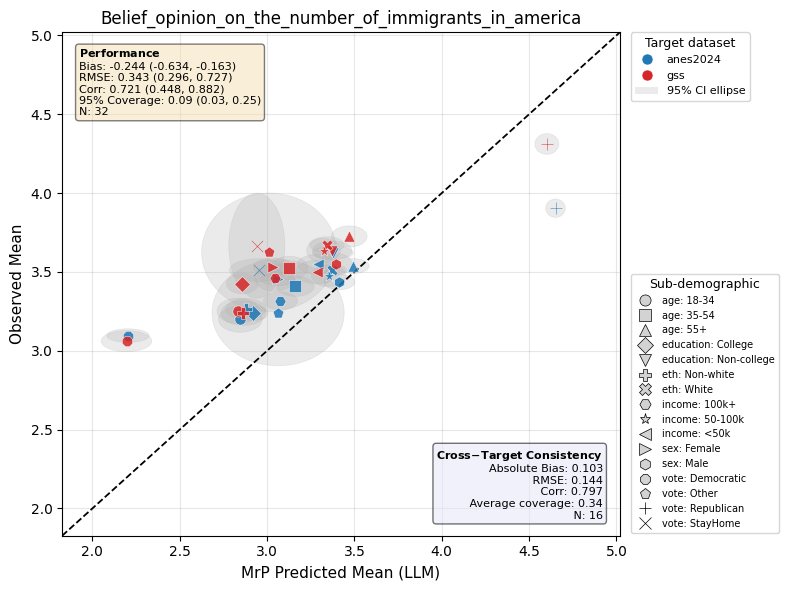

In [43]:
qid = 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol'
subset = plot_df[plot_df['question_id'] == qid]

# Main LLM-vs-observed metrics
metrics = compute_metrics(subset)

# Ceiling metrics from agreement between observed benchmarks
pairwise_df = compute_obs_pairwise(subset)
ceiling_metrics = compute_obs_pairwise_metrics(pairwise_df, ci_level=95)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plot_scatter_with_uncertainty_ellipses(
    ax, plot_df, metrics,
    ci_level=95,
    question_id=qid,
    benchmark=None,
    ceiling_metrics=ceiling_metrics
 )

plt.tight_layout()
plt.savefig('validation_and_ceiling.png', dpi=150, bbox_inches='tight')
plt.show()

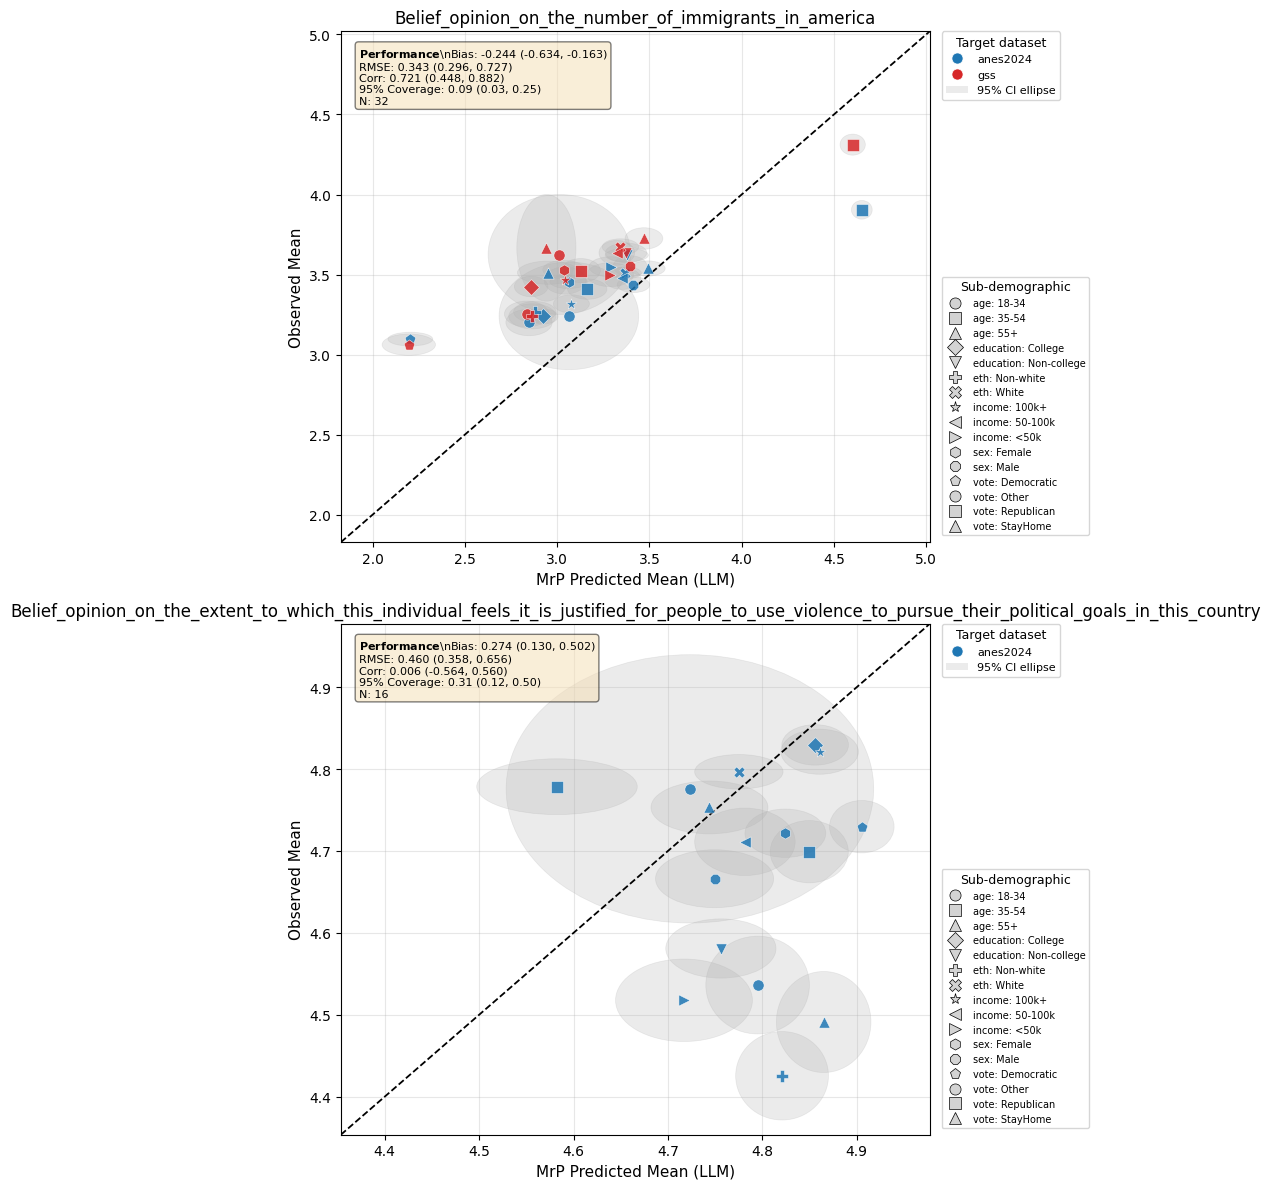

In [26]:
questions = plot_df['question_id'].unique()

fig, axes = plt.subplots(
    nrows=len(questions), ncols=1,
    figsize=(11, 6 * len(questions))
)
if len(questions) == 1:
    axes = [axes]

for ax, qid in zip(axes, questions):
    subset = plot_df[plot_df['question_id'] == qid]
    metrics = compute_metrics(subset)
    plot_scatter_with_uncertainty_ellipses(
        ax, plot_df, metrics,
        ci_level=95, question_id=qid, benchmark=None
    )

plt.tight_layout(rect=[0, 0, 0.76, 1])
plt.savefig('validation_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# boostrap on the sample level (across demographics)